<회귀모델 이름>
 * 선형회귀모델(단일, 다항, 다중), 릿지, 라쏘 등등
 * KNN
 * 앙상블 모델
  - 회귀와 분류에서 모두 사용가능한 모델
  - 랜덤포레스트, 엑스트라트리, 그레디언트 부스팅, 히스토그램 그레디언트 부스팅
  - XGBoosting 등등
 * 회귀와 분류에서 모두 사용가능한 모델 : KNN, 앙상블모델 전체
 * 모델링시 주로 사용되는 모델 XGBoosting, 릿지, 라쏘, 랜덤포레스트

## FIT(훈련), SCORE(정확도), PREDICT(정확도) 함수 꼭 외워두기 !!!!!

### 라이브러리 불러들이기

In [1]:
import pandas as pd
import numpy as np

### 사용할 라이브러리 불러들이기

# 데이터 조작을 위한 라이브러리
import pandas as pd

# 기본 시각화 라이브러리
import matplotlib.pyplot as plt

# 통계적 시각화 라이브러리(보통 기본 시각화보다 향상된 라이브러리라고 생각하면 됨)
import seaborn as sns

# 시각화 시 그래프의 너비/높이 기본 설정하기(단위=인치)
plt.rcParams["figure.figsize"] = (12, 5)

# 시각화시 한글 깨짐 처리를 위한 폰트 지정(Window OS 기준, Mac OS나 Linux는 그에 맞게)
plt.rcParams['font.family'] = 'Malgun Gothic'

# 시각화시 마이너스(-) 기호 깨짐 방지 처리
plt.rcParams['axes.unicode_minus'] = False

### 훈련 및 테스트로 분리하는 함수
from sklearn.model_selection import train_test_split

### 사용할 모델(KNN, 선형회귀(단일, 다항, 다중))
# KNN 모델
from sklearn.neighbors import KNeighborsRegressor
# 선형회귀 모델
from sklearn.linear_model import LinearRegression

### 모델 예측 평가지표 확인
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 사용할 데이터 정의하기(농어의 길이와 무게)

In [2]:
### 농어의 길이
perch_length= np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )


### 농어 무게
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

# np.array : 그냥 리스트라 보면 됨.




In [3]:
### 2개 데이터셋 갯수(차원) 확인
perch_length.shape, perch_weight.shape

((56,), (56,))

In [4]:
"""
<분석 주제>
- 농어의 길이만으로 -> 무게 예측하기
- 독립변수(문제) : perch_length
- 종속변수(정답) : perch_weight
"""

'\n<분석 주제>\n- 농어의 길이만으로 -> 무게 예측하기\n- 독립변수(문제) : perch_length\n- 종속변수(정답) : perch_weight\n'

#### 산점도 그래프를 이용하여 데이터 분포 확인하기

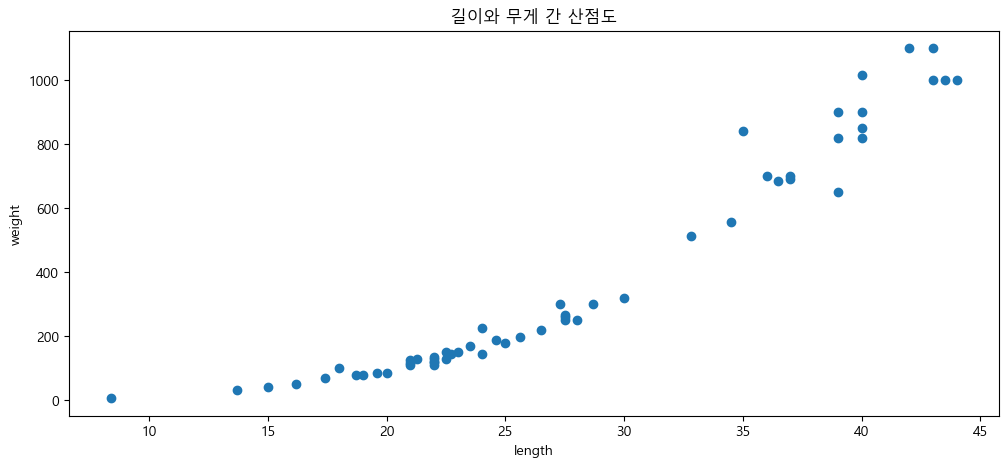

In [5]:
### 길이(x축)와 무게(y축) 간의 산점도(scatter) 그래프 시각화하기
plt.title("길이와 무게 간 산점도")

# 산점도 그래프 그리기
plt.scatter(perch_length, perch_weight)

# 축제목 넣기
plt.xlabel("length")
plt.ylabel("weight")

plt.show()

### 분포 형태(선형성 - 직선/곡선을 띄고 있는지 확인)
### (해석)
# - x축의 길이가 커질수록, y축의 무게가 커지는 우상향의 양의 상관관계를 나타내고 있음
# - 좌하향은 곡선을 보이고 있으며, x축의 중간이후 직선을 보이고 있음
# - 독립변수 길이를 이용하여, 종속변수 무게를 예측하기 위해서는
#   --> 우상향 선형을 해석할 수 있는 선형모델인 회귀모델을 사용하는 것이 타당함


# - 선형모델 : 회귀모델을 사용
# - 선형에는 직선, 곡선, 포물선이 있음
# - 직선 : 직선의 방정식 사용(y=ax + b)
#        : a는 기울기(가중치라고 칭합니다.), b는 y절편
# - 곡선 : 곡선의 방정식 사용(y=ax^2 + bx + c)
#        : a와 b는 기울기(가중치), c는 y절편
# - 포물선 : 포물선 방정식(y=ax1 + bx2, + cx3 .... N)
#         : a,b,c...는 기울기(가중치), N은 y절편


# - 우리가 알고 있는 값 : 지도학습이므로, 독립변수(x)와 종속변수(y)
# - 모델이 훈련(학습, 공부)하면서 찾아내는 값 : 기울기, y절편 (선형의 패턴 찾아냄)

### 데이터 분리하기(훈련 : 테스트 = 0.75 : 0.25로 분리하기)

In [6]:
"""
* 데이터는 훈련 : 테스트 = 0.75 : 0.25로 분리
* 훈련 변수명 : train_input, train_target
* 테스트 변수명 : test_input, test_target
"""
### stratify 속성은 분류분석에서만 사용됨(회귀에서는 사용하면 오류)
train_input, test_input, train_target, test_target = train_test_split(perch_length, perch_weight, test_size = 0.25, random_state=42)
print(train_input.shape, train_target.shape)
print(test_input.shape, test_target.shape)


(42,) (42,)
(14,) (14,)


### 모델 훈련에 맞는 데이터의 차원 맞추기

In [7]:
### 독립변수는 무조건 2차원이어야 한다.
# - 훈련 및 테스트 데이터의 독립변수 차원을 2차원으로 재조정하기
# - (42, 1), (14, 1)
# - reshape(행, 열) : 넘파이(numpy) 라이브러리에서 제공되는 함수
#   -> 새로운 차원으로 만들 행에 -1은 전체 행을 의미함
#   -> 새로운 차원으로 만들 열을 1열로 추가
train_input = train_input.reshape(-1, 1) #이건 한번만 실행해야함!
print(train_input.shape)
test_input = test_input.reshape(-1, 1)
print(test_input.shape)


(42, 1)
(14, 1)


### 모델링 하기

### 사용할 모델 : KNN 회귀모델

<머신러닝 분류 분석>
 - 사용모델 : k-최근접 이웃모델(KNN : K-Nearest Neighbors)
 - 머신러닝에서 가장 간단한 모델
 - 다른 모델들과 비교시에 사용되기도 함(현장에서는 많이 사용 안함)


<KNN 처리 방식>
 - 예측값과 가장 가까운 이웃의 갯수의 비율을 이용하여
 - 가까운 이웃의 비율이 높은(많은) 쪽에 속한 무게들의 평균을 제공해주는 방식


<사용 라이브러리>
 - 사용 패키지 : sklearn.neighbors
 - 사용 모델(클래스) : KNeighborsRegressor
 - 분류모델들은 이름 뒤에 Classifier가 붙어 있음
 - 회귀모델들은 이름 뒤에 Regressor가 붙어 있음


In [ ]:
### 1. 모델 생성하기
# - n_neighbors : 예측에 사용할 가장가까운 이웃의 갯수 정의(기본값=5 또는 사람이 정의)
#               : 주로 사용되는 값은 3, 5이며, 홀수로 지정
# (하이퍼파라메터 : 사람이 관여해서 값을 수정하는 변수들.. 
#               -> 모델의 예측 성능에 영향을 미치는 변수들임 = 성능을 조정하는 변수)
knr = KNeighborsRegressor() #클래스 생성(일반적으로 클래스는 무조건 생성해줘야함)
knr

### 2. 모델 훈련시키기(= 패턴 찾기)
# - 훈련 : 회귀에서는 기울기(가중치-weight)와 y절편을 찾는 것
# - fit(훈련 독립변수, 훈련 종속변수) : 지도학습(문제, 정답)
# - 매우 중요**** : fit() 훈련 함수에는 훈련데이터만 사용하며, 검증/테스트 데이터는 사용하지 않음****
knr.fit(train_input, train_target)

### 3. 훈련 및 테스트의 독립변수/종속변수를 이용하여 정확도(결정계수) 확인하기
# - 회귀분석에서는 훈련에 대해 정확도라고하지 않고, 결정계수(R2)라고 칭합니다.
# - 정확도는 확률(%), 결정계수는 추정치를 의미함(정확한 값이 아님, 오차가 있음)
# - 사용하는 함수 : score(독립변수, 종속변수)
#   <score 함수 내에서 처리되는 구조>
#     1. 독립변수를 이용해서 예측(훈련(fit)된 결과를 이용해서 예측)
#     2. 예측한 결과(Yn)와 실제 정답(넣어준 종속변수)과 비교하여 결과를 출력
#     3. 결과값 : 0~1 범위의 값(1에 가까울수록 예측을 잘함)
#               : 표현 단어 (예측력이 좋다. 결정력이 좋다. 라고 표현함)

#훈련 결정계수 확인
trian_score = knr.score(train_input, train_target)
# 테스트 결정계수 확인
test_score = knr.score(test_input, test_target)
print(trian_score, test_score) # %를 나타냄 / 성능을 나타내는 지표이지 정확히 96%다. 는 아님

### (과적합 여부 해석(판단))
# - 가장 이상적인 기준 : 훈련 > 검증 > 테스트 (또는 훈련 > 검증 < 테스트) (또는 훈련 = 검증 = 테스트)
# - 가상 이상적인 기준을 일반화가 잘된 모델이라고 표현

# <과적합 구분> (3개인 경우(훈련:검증:테스트) 훈련값과 검증값에 대한 차이)
# - 과소적합 : 훈련 < 검증 인 경우 (0.01이라도 작게 나오면 과소적합임)
# - 과대적합 : 훈련이 1.0 또는 훈련과 검증의 차이가 보통 0.1 이상인 경우
# - 처리방법 : 더 이상 진행하지 않고 과소 적합을 해소하기 위해 이전 단계로 돌아감(하이퍼파라미터 튜닝)

### 4. 예측하기 : 검증 또는 테스트 데이터 사용
# - 독립변수(문제)만 사용(값은 1개 또는 그 이상)
train_pred = knr.predict(train_input)
print(train_pred) # 예측한 값
print(train_target) # 실제 값

test_pred = knr.predict(test_input)
print(test_pred) # 예측한 값
print(test_target) # 실제 값

0.9698823289099254 0.992809406101064
[  88.6  123.    79.6   70.6  723.   193.   847.   847.  1010.   123.
   95.   123.   174.   248.  1010.   847.   174.   113.   248.   847.
  659.   224.   723.    60.   140.    60.   719.   694.2  248.   167.
  847.   113.   168.   123.  1010.   136.    79.6  719.   123.   193.
  990.   659. ]
[  85.  135.   78.   70.  700.  180.  850.  820. 1000.  120.   85.  130.
  225.  260. 1100.  900.  145.  115.  265. 1015.  514.  218.  685.   32.
  145.   40.  690.  840.  300.  170.  650.  110.  150.  110. 1000.  150.
   80.  700.  120.  197. 1100.  556.]
[  60.    79.6  248.   122.   136.   847.   311.4  183.4  847.   113.
 1010.    60.   248.   248. ]
[   5.9  100.   250.   130.   130.   820.   320.   188.   900.   125.
 1000.    51.5  250.   300. ]


### 회귀모델 오차 확인

In [9]:
"""
<회귀모델 오차 확인 방법>
 - 평균절대오차(MAE, Mean Absolute Error)
 - 평균제곱오차(MSE, Mean Squere Error)
 - 보통 평균절대오차(MAE)를 이용하여 모델간의 성능 비교 평가 시 사용됨
 - 비교 평가는 모델 선정의 기준이 된다는 의미임


<오차 확인 순서>
 1. 훈련 모델을 이용하여 예측(Predict)
 2. 예측 결과와 종속변수(정답)를 이용하여 오차 확인(주로 테스트 데이터를 활용)


<사용 라이브러리>
 - 패키지 : sklearn.metrics
 - 사용함수 : mean_absolute_error, mean_squere_error
"""

'\n<회귀모델 오차 확인 방법>\n - 평균절대오차(MAE, Mean Absolute Error)\n - 평균제곱오차(MSE, Mean Squere Error)\n - 보통 평균절대오차(MAE)를 이용하여 모델간의 성능 비교 평가 시 사용됨\n - 비교 평가는 모델 선정의 기준이 된다는 의미임\n\n\n<오차 확인 순서>\n 1. 훈련 모델을 이용하여 예측(Predict)\n 2. 예측 결과와 종속변수(정답)를 이용하여 오차 확인(주로 테스트 데이터를 활용)\n\n\n<사용 라이브러리>\n - 패키지 : sklearn.metrics\n - 사용함수 : mean_absolute_error, mean_squere_error\n'

In [10]:
### 1. 테스트 데이터로 예측하기
# - 위에서 예측한 결과 사용 : test_pred 변수 사용

### 2. 오차 확인
# - mean_absolute_error(정답, 예측값)
mae = mean_absolute_error(test_target, test_pred)
print(mae)

# - mean_squared_error(정답, 예측값)
mse = mean_squared_error(test_target, test_pred)
print(mse)

"""
(해석)
- KNN 회귀모델을 이용할 경우,
  농어의 길이를 이용하여 농의 무게를 예측하고자 할 경우에는
  약 +- 19.157 정도의 오차가 발생하는 모델임(MAE 기준)
"""

19.157142857142862
721.7385714285714


'\n(해석)\n- KNN 회귀모델을 이용할 경우,\n  농어의 길이를 이용하여 농의 무게를 예측하고자 할 경우에는\n  약 +- 19.157 정도의 오차가 발생하는 모델임(MAE 기준)\n'

### 성능 향상 시키기 

In [11]:
"""(회귀 및 분류분석 모두 공통 적용 사항)
<정확도 향상 방법 1 - 과적합 여부 판단하기>
 - 훈련정확도와 검증(또는 테스트)정확도 비교
 - 훈련정확도 < 검증(또는 테스트) 정확도 ==> 과소적합
 - 훈련정확도 > 검증(또는 테스트) 정확도
   --> 값의 차이가 0.1(0.05) 이상인 경우 ==> 과대 적합이 보인다고 표현함
 - 훈련정확도가 1인 경우 ==> 과대적합
 
<과적합에 따른 모델 판단 여부>
 - 과소적합 : 모델 사용 못함
 - 과대적합 : 훈련정확도가 1인 경우 -> 모델 사용 못함
 - 과대적합 : 0.1 이상 차이인 경우 -> 모델 향상(하이퍼파라메터 튜닝)을 위한 노력 필요
 - 일반화   : 0.1 이내 차이인 경우 -> 모델 사용 가능(하이퍼파라메터 튜닝이 가능하면 수행)
 ** 위에서 0.1 범위는 통상적인 범위이며, 기준은 아님
 
<해결방법>
 - 데이터 양을 늘리기(마지막 해결방법)
 - 특성이 여러개인 경우 데이터스케일링 (정규화(표준화)) 하기
 - 하이퍼파라메터 튜닝하기
 - 다른 모델 사용하기
"""

'(회귀 및 분류분석 모두 공통 적용 사항)\n<정확도 향상 방법 1 - 과적합 여부 판단하기>\n - 훈련정확도와 검증(또는 테스트)정확도 비교\n - 훈련정확도 < 검증(또는 테스트) 정확도 ==> 과소적합\n - 훈련정확도 > 검증(또는 테스트) 정확도\n   --> 값의 차이가 0.1(0.05) 이상인 경우 ==> 과대 적합이 보인다고 표현함\n - 훈련정확도가 1인 경우 ==> 과대적합\n \n<과적합에 따른 모델 판단 여부>\n - 과소적합 : 모델 사용 못함\n - 과대적합 : 훈련정확도가 1인 경우 -> 모델 사용 못함\n - 과대적합 : 0.1 이상 차이인 경우 -> 모델 향상(하이퍼파라메터 튜닝)을 위한 노력 필요\n - 일반화   : 0.1 이내 차이인 경우 -> 모델 사용 가능(하이퍼파라메터 튜닝이 가능하면 수행)\n ** 위에서 0.1 범위는 통상적인 범위이며, 기준은 아님\n \n<해결방법>\n - 데이터 양을 늘리기(마지막 해결방법)\n - 특성이 여러개인 경우 데이터스케일링 (정규화(표준화)) 하기\n - 하이퍼파라메터 튜닝하기\n - 다른 모델 사용하기\n'

### 과적합 여부 확인하기

In [12]:
#훈련 결정계수 확인
trian_score = knr.score(train_input, train_target)
# 테스트 결정계수 확인
test_score = knr.score(test_input, test_target)
print(trian_score, test_score, trian_score - test_score) # %를 나타냄 / 성능을 나타내는 지표이지 정확히 96%다. 는 아님

### (과적합 여부 해석)
# - 훈련정확도가 테스트정확도보다 낮기 때문에
# - 예측 모델로 사용하기에는 부적합한 모델임(과소적합)
# - 즉, 과소저합이 발생한 모델임
# - 더 이상 예측 과정은 불필요함


### (과소적합 해결을 위한 방법)
# - 데이터 추가 수집(최후의 방법) : x
# - 데이터스케일링(정규화(표준화)) : o (독립변수가 하나라 굳이. 단위 차이 비교대상 없음.)
# - 하이퍼파라메터 튜닝 : o (즉시 가능)
# - 다른 모델 사용 : o (현재는 KNN으로만)


0.9698823289099254 0.992809406101064 -0.022927077191138623


In [13]:
### ### 각 모델별로 성능에 영향을 미치는 변수들이 있음
# - 이런 변수들을 하이퍼파라메터라고 칭함
# - KNN 모델에서는 이웃의갯수(n_neighbors)가 해당됨
# - 하이퍼파라메터 : 사람에 의해 "성능에 영향을 미치는 값"을 수정하는 대상 변수
# - 모델(클래스) 생성시 또는 생성 후에 하이퍼파라메터 변수의 값을 정의할 수 있음

In [14]:
### 클래스 생성
knr = KNeighborsRegressor(n_neighbors=3)

### 훈련시키기(훈련데이터의 독립/종속변수만 사용)
knr.fit(train_input, train_target)

### 훈련 및 테스트 정확도(결정계수) 계산
# - score(훈련 독립, 종속)
trian_score = knr.score(train_input, train_target)

# - score(테스트 독립, 종속)
test_score = knr.score(test_input, test_target)

### 과적합 여부 해석
# - 훈련 결정계수가 테스트 결정계수보다 크기에 과소적합은 발생하지는 않았으며,
# - 훈련과 테스트의 결정계수의 차이가 0.006으로 과대적합이 일어나지 않은
# - 일반화된 모델로 판단(결정)됨.
print(trian_score, test_score, trian_score - test_score)


0.9804899950518966 0.9746459963987609 0.005843998653135674


In [15]:
### 클래스 생성
knr = KNeighborsRegressor(n_neighbors=7)

### 훈련시키기
knr.fit(train_input, train_target)

### 훈련 및 테스트 정확도(결정계수) 계산
trian_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)

### 과적합 여부 해석
# - 과소적합 발생
print(trian_score, test_score, trian_score - test_score)


0.9761170732051527 0.9781383949643516 -0.002021321759198891


In [16]:
### 클래스 생성
knr = KNeighborsRegressor(n_neighbors=9)

### 훈련시키기
knr.fit(train_input, train_target)

### 훈련 및 테스트 정확도(결정계수) 계산
trian_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)

### 과적합 여부 해석
# - 훈련 결정계수가 테스트 결정계수보다 크기에 과소적합은 발생하지는 않았으며,
# - 훈련과 테스트의 결정계수의 차이가 0.0001으로 과대적합이 일어나지 않은
# - 일반화된 모델로 판단되나, 이웃을 3으로 했을 때가 더 긍정적 결과.
print(trian_score, test_score, trian_score - test_score)


0.9693310367551284 0.9692647749722698 6.626178285862316e-05


In [17]:
### KNN 하이퍼파라메터 변수 : 이웃의 갯수
# 훈련정확도가 1이 아니면서, 가장 높은 정확도(결정계수) 시점의 이웃의 갯수 찾아내주세요..
# - 찾은 다음 훈련 및 테스트 정확도 확인하여 비교해 주세요..

### 테스트할 이웃의 갯수 범위 지정
# - 전체 데이터의 갯수 = 49건(전체 이웃은 의미가 없음)
# - 최소=3 , 최대=49, 홀수 갯수만 테스트(기본적으론 3, 5(디폴트), 7, 9)


### 최종 출력 결과 : 결정계수(훈련 및 테스트 정확도), 이웃의 갯수
max_score_test = 0
max_score = 0
best_n = 0
n = 1
while n < 41:
    n += 2
    knr = KNeighborsRegressor(n_neighbors=n)

    ### 훈련시키기
    knr.fit(train_input, train_target)

    ### 훈련 및 테스트 정확도(결정계수) 계산
    train_score = knr.score(train_input, train_target)
    test_score = knr.score(test_input, test_target)
    train_test_m = train_score - test_score

    ### 최적의 훈련 및 테스트 정확도
    if (train_score != 1) & (train_score > max_score):
        max_score = train_score
        max_score_test = test_score
        train_test_m1 = max_score - max_score_test
        best_n = n

    print(train_score, test_score, train_test_m, n)

print("---------------------[최적]----------------------")        
print(f"가장 높은 정확도 시점의 이웃 갯수는 {best_n} 입니다.")
print(max_score, max_score_test, train_test_m1)

"""
<결과 해석>
- 훈련정확도가 가장 높을 시점의 이웃의 갯수는 3이며 일반화는 잘 되었음,
- 가장 일반화가 잘된 시점의 이웃의 갯수는 9로 분석되었음
- 단, 훈련정확도는 일반화가 잘된 9일 때보다, 3일때가 가장 높았음

회사 입장이라면 3을 선택할 것.
학자 입장이라면 9를 선택할 것.
"""


0.9804899950518966 0.9746459963987609 0.005843998653135674 3
0.9698823289099254 0.992809406101064 -0.022927077191138623 5
0.9761170732051527 0.9781383949643516 -0.002021321759198891 7
0.9693310367551284 0.9692647749722698 6.626178285862316e-05 9
0.9515761381539326 0.970279643030474 -0.018703504876541377 11
0.9413423450130075 0.9639044643206888 -0.02256211930768126 13
0.930201118360776 0.9554827691127018 -0.025281650751925788 15
0.9087778943199959 0.9314058693169347 -0.022627974996938804 17
0.8782082893573573 0.900993697623706 -0.022785408266348672 19
0.8410922229110086 0.8596922255009882 -0.018600002589979625 21
0.7915879473391005 0.8146418957364303 -0.02305394839732977 23
0.7452999142836829 0.7667897994036779 -0.021489885119994945 25
0.6908904295441316 0.7131817408006262 -0.02229131125649464 27
0.6245508306350807 0.6429925427310261 -0.018441712095945473 29
0.5505387544219442 0.5653184638150339 -0.014779709393089702 31
0.4752451966763833 0.4834613125728193 -0.008216115896436005 33
0.39

'\n<결과 해석>\n- 훈련정확도가 가장 높을 시점의 이웃의 갯수는 3이며 일반화는 잘 되었음,\n- 가장 일반화가 잘된 시점의 이웃의 갯수는 9로 분석되었음\n- 단, 훈련정확도는 일반화가 잘된 9일 때보다, 3일때가 가장 높았음\n\n회사 입장이라면 3을 선택할 것.\n학자 입장이라면 9를 선택할 것.\n'

In [34]:
### for 문 코드
### 가장 높은 훈련 정확도(결정계수)를 저장해 놓을 변수 정의
max_train_score = 0
max_test_score = 0
### 가장 높은 훈련 정확도일 떄의 n의 값을 저장해놓을 변수 정의
max_n = 0

for n in range(3, len(train_input), 2):
    knr = KNeighborsRegressor(n_neighbors=n)

    knr.fit(train_input, train_target)

    train_score = knr.score(train_input, train_target)
    test_score = knr.score(test_input, test_target)

    if train_score < 1:
        if train_score > max_train_score:
            max_train_score = train_score
            max_test_score = test_score
            max_n = n

print(f"가장 높은 정확도 시점의 이웃 갯수는 {max_n} 입니다.")
print(max_train_score, max_test_score)

가장 높은 정확도 시점의 이웃 갯수는 3 입니다.
0.9804899950518966 0.9746459963987609


In [35]:
len(train_input)

42

In [19]:
### 결정된 이웃의 갯수로 모델 훈련 시키기
### 클래스 생성
knr = KNeighborsRegressor(n_neighbors=max_n)

### 훈련시키기
knr.fit(train_input, train_target)

### 훈련 및 테스트 정확도(결정계수) 계산
train_score = knr.score(train_input, train_target)
test_score = knr.score(test_input, test_target)

### 과적합 여부 해석
# - 훈련 결정계수가 테스트 결정계수보다 크기에 과소적합은 발생하지는 않았으며,
# - 훈련과 테스트의 결정계수의 차이가 0.0001으로 과대적합이 일어나지 않은
# - 일반화된 모델로 판단되나, 이웃을 3으로 했을 때가 더 긍정적 결과.
print(train_score, test_score, train_score - test_score)


0.9804899950518966 0.9746459963987609 0.005843998653135674


### 오차 확인하기(MAE, MSE)

In [20]:
### 4. 예측하기 : 검증 또는 테스트 데이터 사용
# - 독립변수(문제)만 사용(값은 1개 또는 그 이상)
test_pred = knr.predict(test_input)
test_pred


### MAE(평균절대오차)
# - mean_absolute_error(정답, 예측값)
mae = mean_absolute_error(test_target, test_pred)
print(mae)

### MSE(평균제곱오차)
# - mean_squared_error(정답, 예측값)
mse = mean_squared_error(test_target, test_pred)
print(mse)

"""
- KNN 모델의 n값을 측정하여 3의 값을 이용할 경우,
  농어의 길이를 이용하여 농의 무게를 예측하고자 할 경우에는
  약 +- 35.42 정도의 오차가 발생하는 모델임(MAE 기준)
"""

35.42380952380951
2544.847142857142


'\n- KNN 모델의 n값을 측정하여 3의 값을 이용할 경우,\n  농어의 길이를 이용하여 농의 무게를 예측하고자 할 경우에는\n  약 +- 35.42 정도의 오차가 발생하는 모델임(MAE 기준)\n'

### 임의의 값 1개로 예측해 보기

In [21]:
### 임의의 값은 예측에 사용할 문제(독립변수: 무조건 2차원!!)를 의미함
# - 임의의 값 50 길이를 이용하여 -> 무게를 예측해 주세요

pred_50 = knr.predict([[50]])
print(f"{pred_50[0]: 3f}") 

type([[50]])

 1033.333333


list

### KNN이 예측에 사용한 이웃 확인하기

In [22]:
### distances(거리) : 임의의값 50을 예측하는데 사용된 이웃과의 거리
### indexes(행 인덱스 번호) : 임의의값 50과 가장 가까운 이웃들의 행 인덱스 번호(훈련 독립변수 데이터 기준)
distances, indexes = knr.kneighbors([[50]])
distances, indexes

(array([[6., 7., 7.]]), array([[34,  8, 14]]))

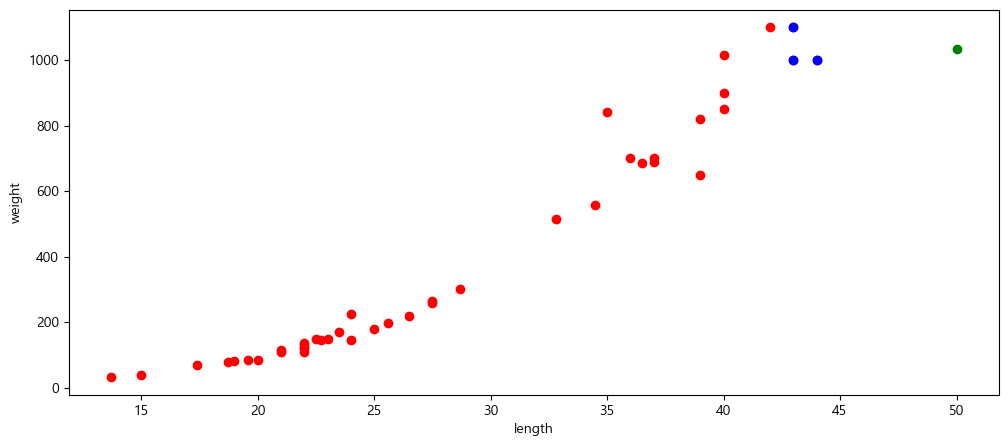

In [23]:
### 훈련데이터, 임의값, 이웃3개 데이터 -> 산점도로 시각화하기

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 이웃 3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")

# - 임의값에 대한 산점도
plt.scatter(50, pred_50[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[1033.33333333]


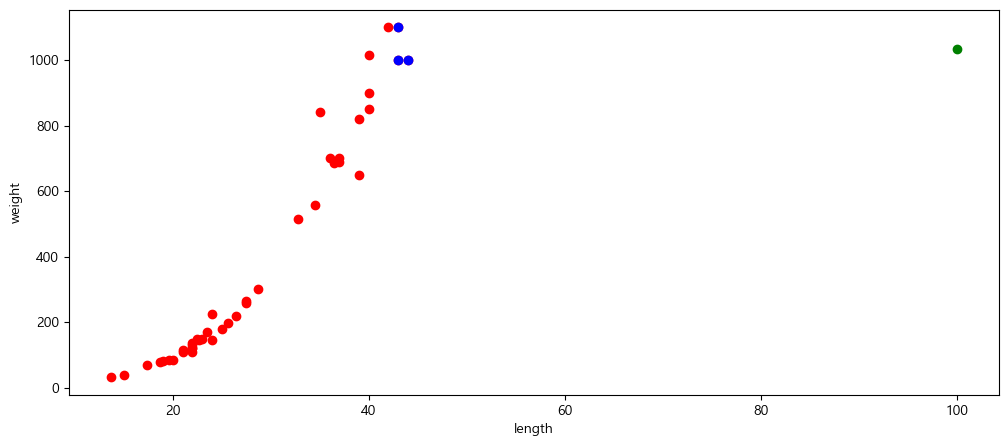

In [24]:
pred= knr.predict([[100]])
print(pred)
distances, indexes = knr.kneighbors([[100]])

### 훈련데이터, 임의값, 이웃3개 데이터 -> 산점도로 시각화하기

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 이웃 3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")

# - 임의값에 대한 산점도
plt.scatter(100, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[1033.33333333]


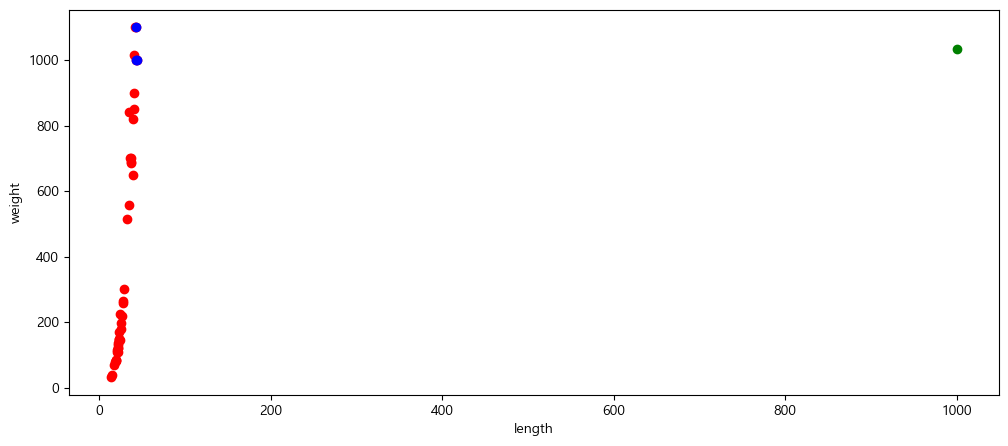

In [25]:
pred= knr.predict([[1000]])
print(pred)
distances, indexes = knr.kneighbors([[1000]])

### 훈련데이터, 임의값, 이웃3개 데이터 -> 산점도로 시각화하기

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 이웃 3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")

# - 임의값에 대한 산점도
plt.scatter(1000, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[200.66666667]


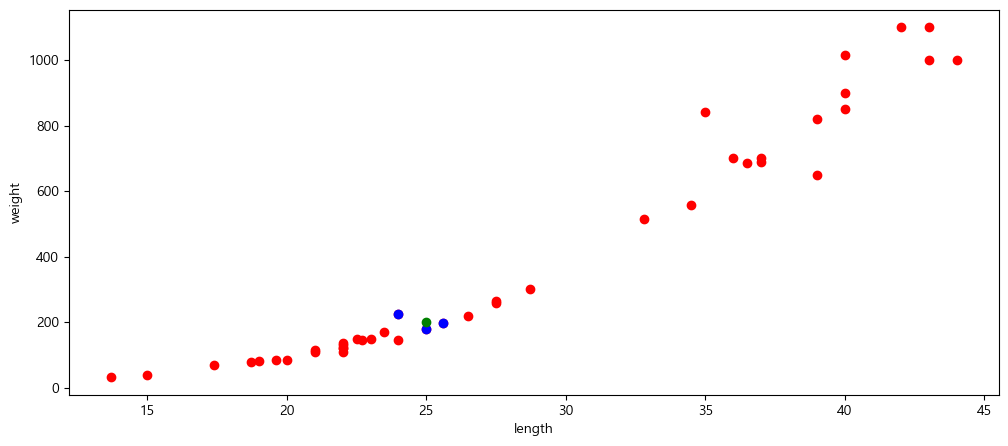

In [26]:
pred= knr.predict([[25]])
print(pred)
distances, indexes = knr.kneighbors([[25]])

### 훈련데이터, 임의값, 이웃3개 데이터 -> 산점도로 시각화하기

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 이웃 3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")

# - 임의값에 대한 산점도
plt.scatter(25, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[47.33333333]


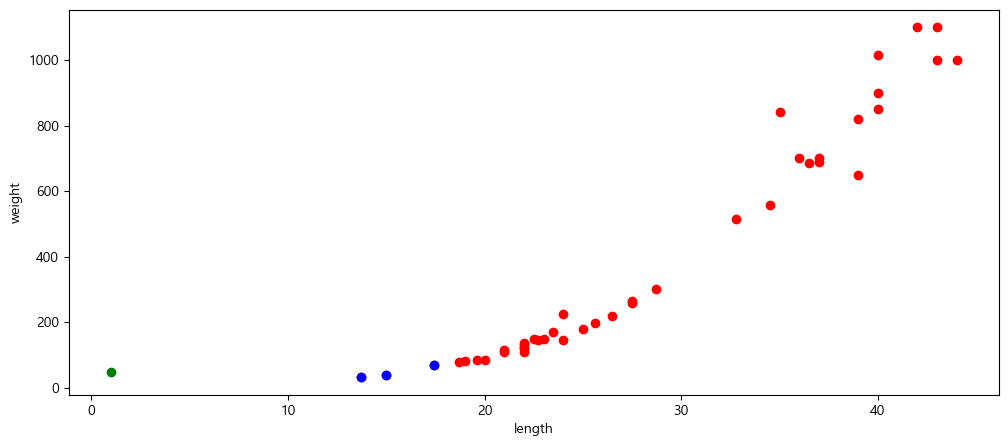

In [27]:
pred= knr.predict([[1]])
print(pred)
distances, indexes = knr.kneighbors([[1]])

### 훈련데이터, 임의값, 이웃3개 데이터 -> 산점도로 시각화하기

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 이웃 3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")

# - 임의값에 대한 산점도
plt.scatter(1, pred[0], c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

[  47.33333333 1033.33333333]


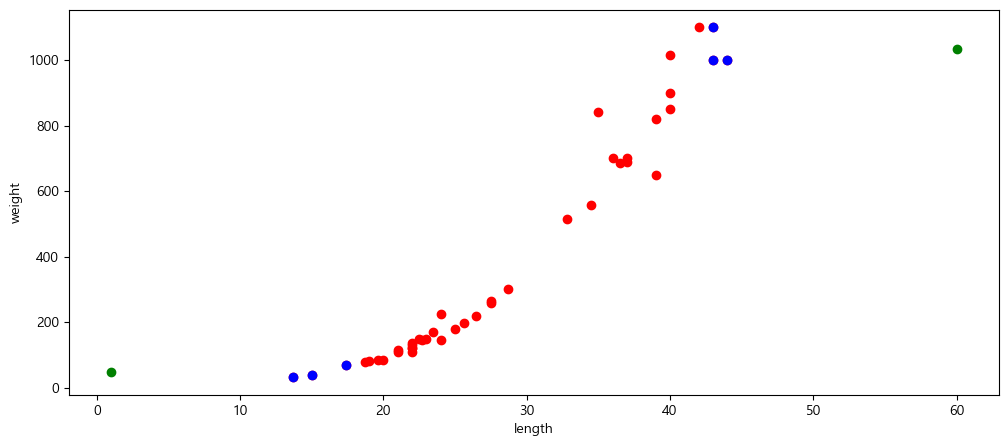

In [28]:
pred= knr.predict([[1], [60]])
print(pred)
distances, indexes = knr.kneighbors([[1], [60]])

### 훈련데이터, 임의값, 이웃3개 데이터 -> 산점도로 시각화하기

# - 훈련데이터에 대한 산점도
plt.scatter(train_input, train_target, c="red", label="train")

# - 이웃 3개에 대한 산점도
plt.scatter(train_input[indexes], train_target[indexes], c="blue", label="n")

# - 임의값에 대한 산점도
plt.scatter([1, 60], pred, c="green", label="pred")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()

In [ ]:
### 다음 과정: 다른 모델도 사용하여 똑같은 과정 돌려보기
### 클래스 생성(분류냐 회귀냐 어떤 클래스?/ knr = KNeighborsRegressor() #클래스 생성(일반적으로 클래스는 무조건 생성해줘야함)) -> fit -> score -> predict -> 오차확인

In [29]:
"""
<KNN의 한계>
 - 예측에 사용된 독립변수의 길이 값이 훈련데이터의 독립변수 최소길이값(min)/최대길이값(max)보다 작거나 큰 경우에는
  --> 항상 같은 무게를 예측하는 오류가 발생하며, 사용되는 이웃의 갯수도 동일함
 - 가장가까운 이웃을 이용하는 모델의 특성 한계 때문에 발생함
 - 훈련데이터의 독립변수 x(길이)의 최소/최대 길이값보다 작거나 큰 값들에 대해서는 예측결과가 불확실함


 ==> 따라서, 다른 모델을 사용해야함
"""

"""
<KNN 모델의 한계를 극복한 모델들>
 * 회귀(Regression) 분석에 사용되는 모델
   - 선형(Linear)인 경우
     -> 선형회귀모델(LinearRegression,
                    선형회귀모델(직선), 다항회귀모델(곡선), 다중회귀모델(포물선) 포함)
        릿지(Ridge), 라쏘(Lasso)


   - 비선형인 경우(앙상블 모델)
     -> 옛날 모델 : 의사결정나무(DecisionTreeRegressor)
     -> 우수 모델 : 랜덤포레스트(RandomForestRegressor) (사용량 多),
                   엑스트라트리(ExtraTreesRegressor)


   - 선형/비선형 모두 가능한 모델
     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingRegressor),
                       히스토그램그레디언트부스트(HistGradientBoostingRegressor),
                       엑스지부스트(XGBRegressor),
                       라이트지비엠(LGBMRegressor) (회귀에서는 잘 안 씀)
                   
 * 분류(Classification) 분석(지도학습)에 사용되는 모델
     -> 옛날 모델 : 의사결정나무(DecisionTreeClassifier)
     -> 우수 모델 : 랜덤포레스트(RandomForestClassifier),
                   엑스트라트리(ExtraTreesClassifier)
     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingClassifier),
                       히스토그램그레디언트부스트(HistGradientBoostingClassifier),
                       엑스지부스트(XGBClassifier),
                       라이트지비엠(LGBMClassifier)
                   
 * 분류분석(비지도학습)의 경우(군집분석)에 사용되는 모델
   - 거리 기반 군집 모델 : K-평균(K-Means)
   - 밀도 기반 군집 모델 : DBSCAN
"""






'\n<KNN 모델의 한계를 극복한 모델들>\n * 회귀(Regression) 분석에 사용되는 모델\n   - 선형(Linear)인 경우\n     -> 선형회귀모델(LinearRegression,\n                    선형회귀모델(직선), 다항회귀모델(곡선), 다중회귀모델(포물선) 포함)\n        릿지(Ridge), 라쏘(Lasso)\n\n\n   - 비선형인 경우(앙상블 모델)\n     -> 옛날 모델 : 의사결정나무(DecisionTreeRegressor)\n     -> 우수 모델 : 랜덤포레스트(RandomForestRegressor) (사용량 多),\n                   엑스트라트리(ExtraTreesRegressor)\n\n\n   - 선형/비선형 모두 가능한 모델\n     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingRegressor),\n                       히스토그램그레디언트부스트(HistGradientBoostingRegressor),\n                       엑스지부스트(XGBRegressor),\n                       라이트지비엠(LGBMRegressor) (회귀에서는 잘 안 씀)\n                   \n * 분류(Classification) 분석(지도학습)에 사용되는 모델\n     -> 옛날 모델 : 의사결정나무(DecisionTreeClassifier)\n     -> 우수 모델 : 랜덤포레스트(RandomForestClassifier),\n                   엑스트라트리(ExtraTreesClassifier)\n     -> 매우 우수 모델 : 그레디언트부스트(GradientBoostingClassifier),\n                       히스토그램그레디언트부스트(HistGradientBoostingClassifier),\n                       